In [63]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import statistics as stats

In [64]:
df=pd.read_csv('Diamond.csv')
df               

,carat,cut,color,clarity,depth,table,weight,size,price
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,326
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,326
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,327
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,334
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,335
...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,5.75,5.76,2757
53936,0.72,Good,D,SI1,63.1,55.0,5.69,5.75,2757
53937,0.70,Very Good,D,SI1,62.8,60.0,5.66,5.68,2757
53938,0.86,Premium,H,SI2,61.0,58.0,6.15,6.12,2757


In [65]:
df.head()

,carat,cut,color,clarity,depth,table,weight,size,price
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,326
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,326
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,327
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,334
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,335


In [66]:
df.tail()

,carat,cut,color,clarity,depth,table,weight,size,price
53935,0.72,Ideal,D,SI1,60.8,57.0,5.75,5.76,2757
53936,0.72,Good,D,SI1,63.1,55.0,5.69,5.75,2757
53937,0.70,Very Good,D,SI1,62.8,60.0,5.66,5.68,2757
53938,0.86,Premium,H,SI2,61.0,58.0,6.15,6.12,2757
53939,0.75,Ideal,D,SI2,62.2,55.0,5.83,5.87,2757


In [6]:
num_col=df.select_dtypes(include="number")
num_col

,carat,depth,table,weight,size,price
0,0.23,61.5,55.0,3.95,3.98,326
1,0.21,59.8,61.0,3.89,3.84,326
2,0.23,56.9,65.0,4.05,4.07,327
3,0.29,62.4,58.0,4.20,4.23,334
4,0.31,63.3,58.0,4.34,4.35,335
...,...,...,...,...,...,...
53935,0.72,60.8,57.0,5.75,5.76,2757
53936,0.72,63.1,55.0,5.69,5.75,2757
53937,0.70,62.8,60.0,5.66,5.68,2757
53938,0.86,61.0,58.0,6.15,6.12,2757


In [8]:
cat_col=df.select_dtypes(include="object")  # or exclude=number
cat_col

,cut,color,clarity
0,Ideal,E,SI2
1,Premium,E,SI1
2,Good,E,VS1
3,Premium,I,VS2
4,Good,J,SI2
...,...,...,...
53935,Ideal,D,SI1
53936,Good,D,SI1
53937,Very Good,D,SI1
53938,Premium,H,SI2


In [17]:
# Using Pandas
print("Using Pandas:\n")  # # \n works only inside a string, such as "Hello\nWorld".
for col in num_col:
    print(f"{col}")
    print("Mean   :", df[col].mean())
    print("Median :", df[col].median())
    print("Mode   :", df[col].mode()[0]) # [0]= First most occuring number/element
    print()

Using Pandas:

carat
Mean   : 0.7979397478680015
Median : 0.7
Mode   : 0.3

depth
Mean   : 61.74940489432702
Median : 61.8
Mode   : 62.0

table
Mean   : 57.45718390804598
Median : 57.0
Mode   : 56.0

weight
Mean   : 5.731157211716722
Median : 5.7
Mode   : 4.37

size
Mean   : 5.734525954764553
Median : 5.71
Mode   : 4.34

price
Mean   : 3932.799721913237
Median : 2401.0
Mode   : 605



In [15]:
# Using Statistics library
print("Using Statistics Library:\n")
for col in num_col:
    print(f"{col}")
    print("Mean   :", stats.mean(df[col]))
    print("Median :", stats.median(df[col]))
    print("Mode   :", stats.mode(df[col]))
    print()

Using Statistics Library:

carat
Mean   : 0.7979397478680015
Median : 0.7
Mode   : 0.3

depth
Mean   : 61.74940489432703
Median : 61.8
Mode   : 62.0

table
Mean   : 57.45718390804598
Median : 57.0
Mode   : 56.0

weight
Mean   : 5.731157211716722
Median : 5.7
Mode   : 4.37

size
Mean   : 5.734525954764553
Median : 5.71
Mode   : 4.34

price
Mean   : 3932.799721913237
Median : 2401.0
Mode   : 605



In [29]:
# Calculate skewness and classify
for col in num_col:
    skew_val = num_col[col].skew()
    if -0.5 <= skew_val <= 0.5:
        category = "Light Skewed"
    elif (-1.5 <= skew_val < -0.5) or (0.5 < skew_val <= 1.5):
        category = "Moderately Skewed"
    else:
        category = "Highly Skewed"
    print(f"{col}: Skewness = {round(skew_val, 2)} --> {category}")

carat: Skewness = 1.12 --> Moderately Skewed
depth: Skewness = -0.08 --> Light Skewed
table: Skewness = 0.8 --> Moderately Skewed
weight: Skewness = 0.38 --> Light Skewed
size: Skewness = 2.43 --> Highly Skewed
price: Skewness = 1.62 --> Highly Skewed


In [69]:
from scipy.stats import boxcox

# Log Transformation
df[['log_size', 'log_price']] = np.log(df[['size', 'price']] + 1)  # Adding 1 to avoid log(0)

# Square Root Transformation
df[['sqrt_size', 'sqrt_price']] = np.sqrt(df[['size', 'price']])

# Cube Root Transformation
df[['cbrt_size', 'cbrt_price']] = np.cbrt(df[['size', 'price']])

# Box-Cox Transformation
# df[['boxcox_size', 'boxcox_price']], _ = boxcox(df[['size', 'price']] + 1)  # scipy.stats.boxcox() expects a 1-dimensional array (1 col. at a time).
df['boxcox_size'], _ = boxcox(df['size'] + 1)
df['boxcox_price'], _ = boxcox(df['price'] + 1)

In [71]:
# Calculate skewness after transformations
transformed_skewness = df[['log_size', 'log_price', 'sqrt_size', 'sqrt_price', 'cbrt_size', 'cbrt_price', 'boxcox_size', 'boxcox_price']].skew()
print("Transformed Skewness:")
print(transformed_skewness)

Transformed Skewness:
log_size        0.006600
log_price       0.115926
sqrt_size       0.363648
sqrt_price      0.844396
cbrt_size      -0.132075
cbrt_price      0.591189
boxcox_size    -0.000807
boxcox_price    0.025726
dtype: float64


Box-cox transformation has given best results.

In [ ]:
UDF and iqr concept python notebooks me dekho

In [74]:
def check_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = series[(series < lower_bound) | (series > upper_bound)]  # Pipe Operator or Bitwise OR Operator
    
    return {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "No. of Outliers": len(outliers)
    }

In [77]:
# Passing numeric variables
for col in num_col:
    result = check_outliers_iqr(df[col])
    
    print(f"\nColumn: {col}")
    for key, value in result.items():
        print(f"{key}: {value}")


Column: carat
Q1: 0.4
Q3: 1.04
IQR: 0.64
Lower Bound: -0.5599999999999999
Upper Bound: 2.0
No. of Outliers: 1889

Column: depth
Q1: 61.0
Q3: 62.5
IQR: 1.5
Lower Bound: 58.75
Upper Bound: 64.75
No. of Outliers: 2545

Column: table
Q1: 56.0
Q3: 59.0
IQR: 3.0
Lower Bound: 51.5
Upper Bound: 63.5
No. of Outliers: 605

Column: weight
Q1: 4.71
Q3: 6.54
IQR: 1.83
Lower Bound: 1.9649999999999999
Upper Bound: 9.285
No. of Outliers: 32

Column: size
Q1: 4.72
Q3: 6.54
IQR: 1.8200000000000003
Lower Bound: 1.9899999999999993
Upper Bound: 9.27
No. of Outliers: 29

Column: price
Q1: 950.0
Q3: 5324.25
IQR: 4374.25
Lower Bound: -5611.375
Upper Bound: 11885.625
No. of Outliers: 3540


In [52]:
from sklearn.preprocessing import LabelEncoder

# Create encoder object
le = LabelEncoder()

# List of categorical columns
#cat_col = ['cut', 'color', 'clarity']

# Apply LabelEncoder to each column
for col in cat_col:
    df[col] = le.fit_transform(df[col])

# Display updated dataframe
print(df.head())

   carat  cut  color  clarity  depth  table  weight  size  price  log_size  \
0   0.23    2      1        3   61.5   55.0    3.95  3.98    326  1.605430   
1   0.21    3      1        2   59.8   61.0    3.89  3.84    326  1.576915   
2   0.23    1      1        4   56.9   65.0    4.05  4.07    327  1.623341   
3   0.29    3      5        5   62.4   58.0    4.20  4.23    334  1.654411   
4   0.31    1      6        3   63.3   58.0    4.34  4.35    335  1.677097   

   log_price  sqrt_size  sqrt_price  cbrt_size  cbrt_price  boxcox_size  \
0   5.789960   1.994994   18.055470   1.584751    6.882389     1.595582   
1   5.789960   1.959592   18.055470   1.565947    6.882389     1.567413   
2   5.793014   2.017424   18.083141   1.596607    6.889419     1.613272   
3   5.814131   2.056696   18.275667   1.617261    6.938232     1.643954   
4   5.817111   2.085665   18.303005   1.632412    6.945150     1.666351   

   boxcox_price  
0      4.793885  
1      4.793885  
2      4.795951  
3      4

In [55]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [53]:
# Standard scaler

std_scaler = StandardScaler()
df_standard_scaled = pd.DataFrame(std_scaler.fit_transform(df), columns=df.columns)
print("Standard Scaled Data:\n")
print(df_standard_scaled.head())

Standard Scaled Data:

      carat       cut     color   clarity     depth     table    weight  \
0 -1.198168 -0.538099 -0.937163 -0.484264 -0.174092 -1.099672 -1.587837   
1 -1.240361  0.434949 -0.937163 -1.064117 -1.360738  1.585529 -1.641325   
2 -1.198168 -1.511147 -0.937163  0.095589 -3.385019  3.375663 -1.498691   
3 -1.071587  0.434949  1.414272  0.675442  0.454133  0.242928 -1.364971   
4 -1.029394 -1.511147  2.002131 -0.484264  1.082358  0.242928 -1.240167   

       size     price  log_size  log_price  sqrt_size  sqrt_price  cbrt_size  \
0 -1.536196 -0.904095 -1.744419  -1.969687  -1.664322   -1.317274  -1.690054   
1 -1.658774 -0.904095 -1.917064  -1.969687  -1.816061   -1.317274  -1.850920   
2 -1.457395 -0.903844 -1.635977  -1.966676  -1.568182   -1.316308  -1.588623   
3 -1.317305 -0.902090 -1.447861  -1.945853  -1.399854   -1.309586  -1.411932   
4 -1.212238 -0.901839 -1.310514  -1.942914  -1.275688   -1.308632  -1.282317   

   cbrt_price  boxcox_size  boxcox_price  
0 

In [56]:
## Min-max scaler

minmax_scaler = MinMaxScaler()
df_minmax_scaled = pd.DataFrame(minmax_scaler.fit_transform(df), columns=df.columns)
print("\nMin-Max Scaled Data:\n")
print(df_minmax_scaled.head())


Min-Max Scaled Data:

      carat   cut     color   clarity     depth     table    weight      size  \
0  0.006237  0.50  0.166667  0.428571  0.513889  0.230769  0.367784  0.067572   
1  0.002079  0.75  0.166667  0.285714  0.466667  0.346154  0.362197  0.065195   
2  0.006237  0.25  0.166667  0.571429  0.386111  0.423077  0.377095  0.069100   
3  0.018711  0.75  0.833333  0.714286  0.538889  0.288462  0.391061  0.071817   
4  0.022869  0.25  1.000000  0.428571  0.563889  0.288462  0.404097  0.073854   

      price  log_size  log_price  sqrt_size  sqrt_price  cbrt_size  \
0  0.000000  0.392269   0.000000   0.259946    0.000000   0.407308   
1  0.000000  0.385302   0.000000   0.255334    0.000000   0.402475   
2  0.000054  0.396645   0.000753   0.262869    0.000232   0.410355   
3  0.000433  0.404237   0.005964   0.267986    0.001848   0.415663   
4  0.000487  0.409780   0.006699   0.271761    0.002078   0.419557   

   cbrt_price  boxcox_size  boxcox_price  
0    0.000000     0.396016

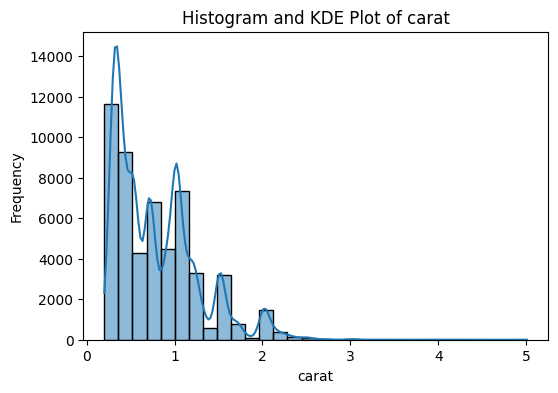

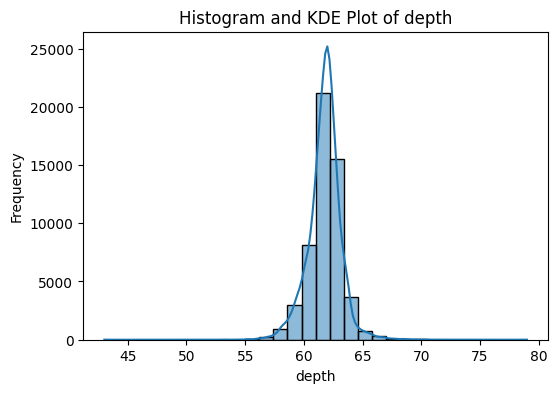

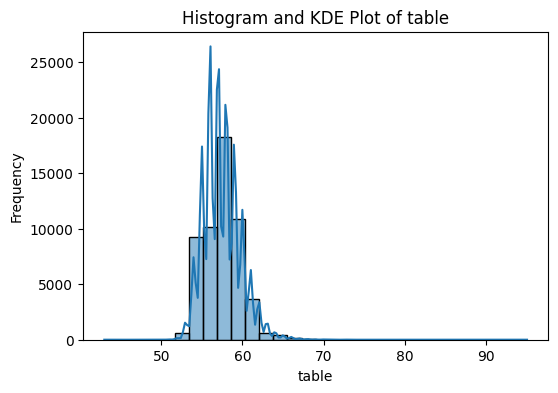

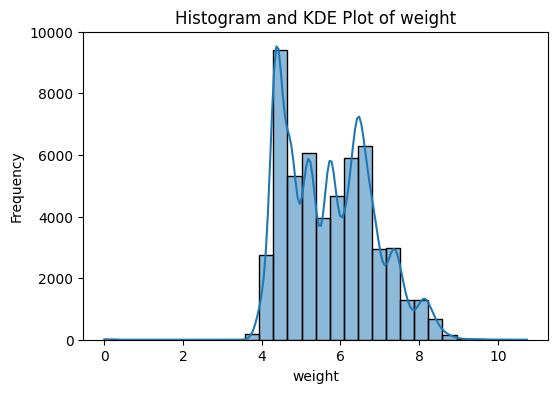

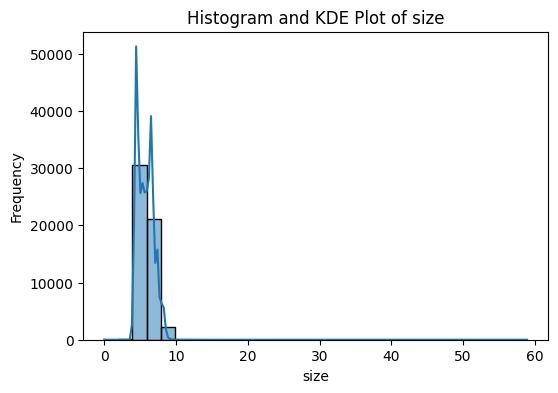

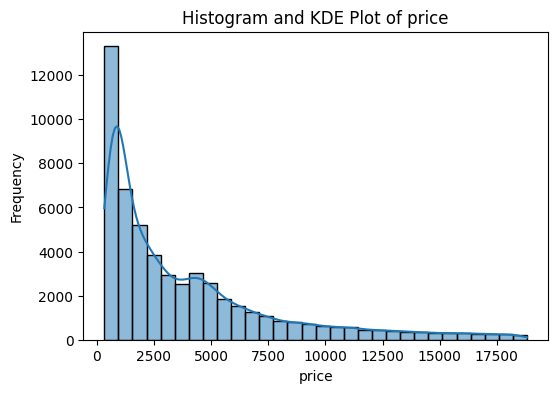

In [58]:
# List of numerical columns
num_col = ['carat', 'depth', 'table', 'weight', 'size', 'price']

# Plot histogram + KDE for each variable
for col in num_col:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Histogram and KDE Plot of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [59]:
## Correlation matrix

corr_matrix = df[num_col].corr()
print(corr_matrix)

           carat     depth     table    weight      size     price
carat   1.000000  0.028224  0.181618  0.975094  0.951722  0.921591
depth   0.028224  1.000000 -0.295779 -0.025289 -0.029341 -0.010647
table   0.181618 -0.295779  1.000000  0.195344  0.183760  0.127134
weight  0.975094 -0.025289  0.195344  1.000000  0.974701  0.884435
size    0.951722 -0.029341  0.183760  0.974701  1.000000  0.865421
price   0.921591 -0.010647  0.127134  0.884435  0.865421  1.000000


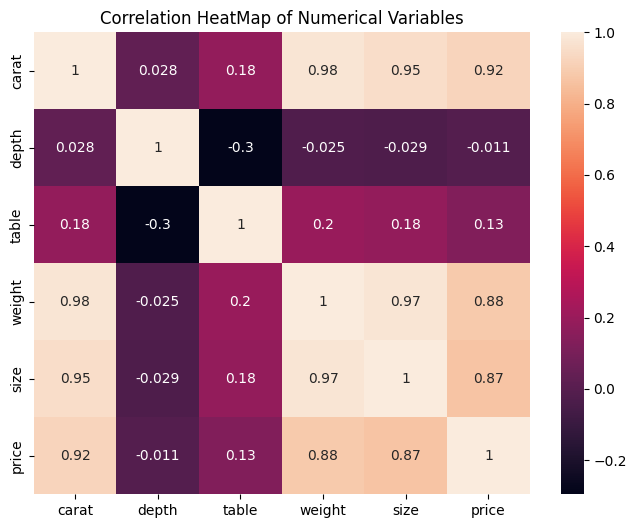

In [62]:
## Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True)

plt.title("Correlation HeatMap of Numerical Variables")
plt.show()

Insight 1: Carat has a very strong positive correlation with price.

Insight 2: Weight has a strong positive correlation with price.

Insight 3: Size has a strong positive correlation with price.

Insight 4: Depth has almost zero correlation with price.